In [64]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [65]:
!wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

--2026-11-13 13:53:59--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt.1’

names.txt.1         100%[===================>] 222.80K  --.-KB/s    in 0.002s  

2026-11-13 13:54:00 (99.0 MB/s) - ‘names.txt.1’ saved [228145/228145]



In [66]:
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [67]:
len(words)

32033

In [68]:
chars = sorted(list(set("".join(words))))
stoi = {s:i for i, s in enumerate(chars, 1)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [69]:
block_size = 5

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + ".":
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)

      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y

import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [70]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 20), generator=g)
W1 = torch.randn((100, 600), generator=g)
b1 = torch.randn((600), generator=g)
W2 = torch.randn((600, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [71]:
sum(p.nelement() for p in parameters)

77367

In [72]:
for p in parameters:
  p.requires_grad = True

In [73]:
ix = torch.randint(0, Xtr.shape[0], (64,))
emb = C[Xtr[ix]].shape
emb, ix.shape

(torch.Size([64, 5, 20]), torch.Size([64]))

In [74]:
lri = []
lossi = []
stepi = []

In [82]:
for i in range(500000):

  ix = torch.randint(0, Xtr.shape[0], (32,))
  emb = C[Xtr[ix]]
  h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Ytr[ix])

  for p in parameters:
    p.grad = None
  loss.backward()

  lr = 0.1 if i < 250000 else 0.01
  for p in parameters:
    p.data += lr*p.grad

  stepi.append(i)
  lossi.append(loss.log10().item())

print(loss.item())



2.227964162826538


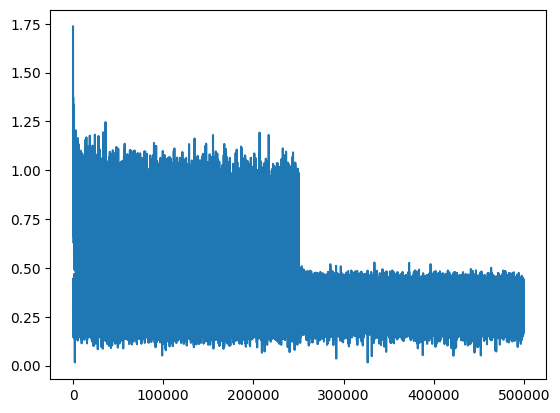

In [83]:
plt.plot(stepi, lossi);

In [85]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.0432, grad_fn=<NllLossBackward0>)

In [86]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1842, grad_fn=<NllLossBackward0>)

In [87]:
emb = C[Xte]
h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1763, grad_fn=<NllLossBackward0>)

In [81]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size
    while True:
      emb = C[torch.tensor([context])]
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

carelle.
alylerl.
kemler.
thiya.
kanden.
jazhuknae.
dirra.
kaeli.
nelene.
jceri.
vonsleigh.
hama.
dinder.
juisha.
leanna.
biion.
elogierry.
ixap.
eunigsa.
medde.


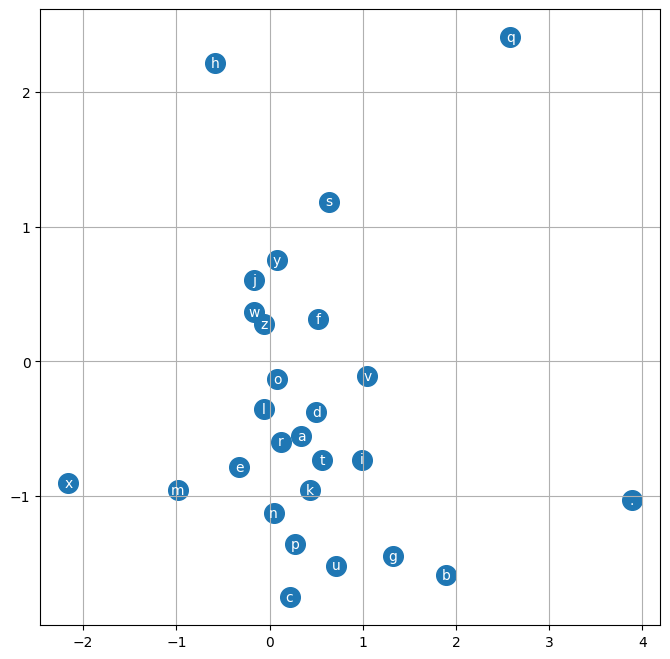

In [88]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')